In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

X_test_enc = pd.read_csv('../data/X_test_enc.csv')
y_test = pd.read_csv('../data/y_test.csv').squeeze()

xgb_model = joblib.load('../src/xgb_final_model.pkl')            # raw trees, for SHAP
xgb_calibrated = joblib.load('../src/xgb_calibrated_model.pkl')   # for the reject/approve decision

print(X_test_enc.shape)

(200, 48)


In [2]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_enc)

print("SHAP values shape:", shap_values.shape)
print("Base value (expected value):", explainer.expected_value)

SHAP values shape: (200, 48)
Base value (expected value): 0.16743782


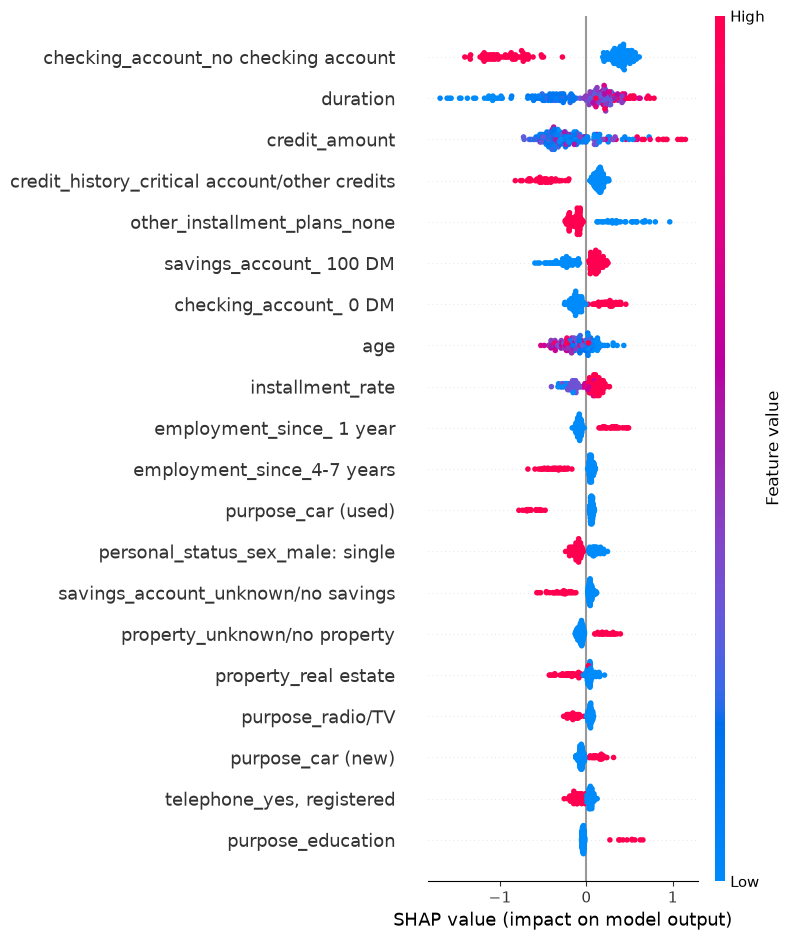

In [3]:
plt.figure()
shap.summary_plot(shap_values, X_test_enc, show=False)
plt.tight_layout()
plt.savefig('../reports/figures/shap_summary_beeswarm.png', dpi=100, bbox_inches='tight')
plt.show()

In [4]:
RECOMMENDED_THRESHOLD = 0.20

calibrated_probs = xgb_calibrated.predict_proba(X_test_enc)[:, 1]
rejected_mask = calibrated_probs >= RECOMMENDED_THRESHOLD
rejected_indices = np.where(rejected_mask)[0]

print(f"Rejected at threshold {RECOMMENDED_THRESHOLD}: {rejected_mask.sum()} out of {len(calibrated_probs)}")
print("First few rejected indices:", rejected_indices[:10])

Rejected at threshold 0.2: 125 out of 200
First few rejected indices: [ 0  2  3  4  5  6  7  8 11 13]


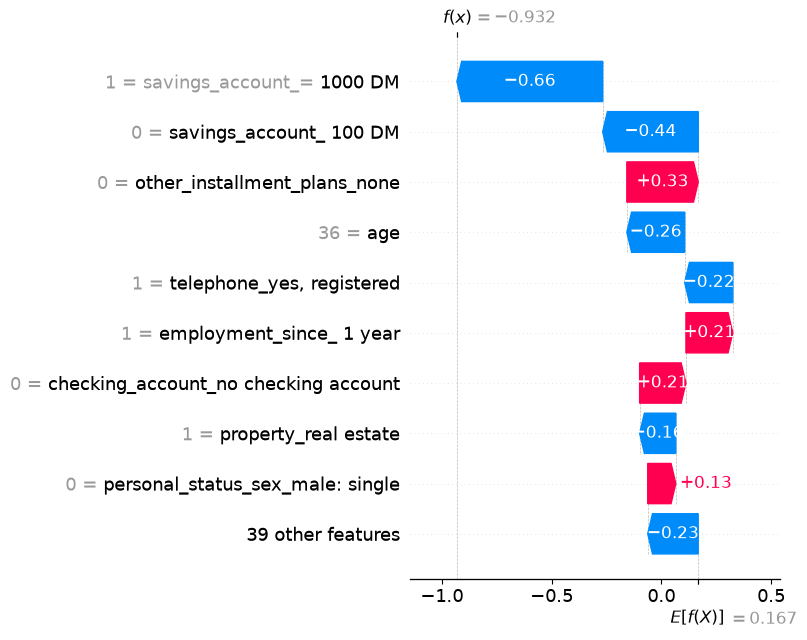

Raw probability: [0.2825668]
Calibrated probability: 0.32132275998592374


In [5]:
example_idx = rejected_indices[0]

shap_explanation = shap.Explanation(
    values=shap_values[example_idx],
    base_values=explainer.expected_value,
    data=X_test_enc.iloc[example_idx],
    feature_names=X_test_enc.columns.tolist()
)

plt.figure()
shap.waterfall_plot(shap_explanation, max_display=10, show=False)
plt.tight_layout()
plt.savefig('../reports/figures/shap_waterfall_example.png', dpi=100, bbox_inches='tight')
plt.show()

print("Raw probability:", xgb_model.predict_proba(X_test_enc.iloc[[example_idx]])[:, 1])
print("Calibrated probability:", calibrated_probs[example_idx])

In [6]:
# Never surfaced as stated reasons in a denial notice (ECOA-protected classes and close proxies)
PROTECTED_FEATURE_PREFIXES = ('personal_status_sex', 'foreign_worker', 'age')

def get_top_risk_factors(idx, shap_values, X_test_enc, top_n=5, exclude_protected=True):
    factor_data = pd.DataFrame({
        'feature': X_test_enc.columns,
        'shap_value': shap_values[idx],
        'feature_value': X_test_enc.iloc[idx].values
    })

    if exclude_protected:
        factor_data = factor_data[~factor_data['feature'].str.startswith(PROTECTED_FEATURE_PREFIXES)]

    risk_factors = factor_data[factor_data['shap_value'] > 0].sort_values('shap_value', ascending=False)
    return risk_factors.head(top_n)

print("Unfiltered top 5 (note the protected attribute):")
print(get_top_risk_factors(example_idx, shap_values, X_test_enc, exclude_protected=False))

print("\nFiltered top 5 (what the notice generator sees):")
print(get_top_risk_factors(example_idx, shap_values, X_test_enc))

Unfiltered top 5 (note the protected attribute):
                                          feature  shap_value  feature_value
39                   other_installment_plans_none    0.325455            0.0
28                       employment_since_ 1 year    0.213547            1.0
9            checking_account_no checking account    0.210895            0.0
33               personal_status_sex_male: single    0.127959            0.0
10  credit_history_critical account/other credits    0.087281            0.0

Filtered top 5 (what the notice generator sees):
                                          feature  shap_value  feature_value
39                   other_installment_plans_none    0.325455            0.0
28                       employment_since_ 1 year    0.213547            1.0
9            checking_account_no checking account    0.210895            0.0
10  credit_history_critical account/other credits    0.087281            0.0
0                                        duration    0

In [7]:
adverse_action_clean = []
for idx in rejected_indices:
    top = get_top_risk_factors(idx, shap_values, X_test_enc, top_n=5)
    adverse_action_clean.append({
        'applicant_index': int(idx),
        'top_factors': [
            {'feature': r.feature, 'shap_value': float(r.shap_value), 'feature_value': float(r.feature_value)}
            for r in top.itertuples()
        ]
    })

zero_factor = [r['applicant_index'] for r in adverse_action_clean if len(r['top_factors']) == 0]
print(f"Built explanations for {len(adverse_action_clean)} rejected applicants")
print("Applicants with zero permissible risk factors:", len(zero_factor))

Built explanations for 125 rejected applicants
Applicants with zero permissible risk factors: 0


In [8]:
with open('../data/adverse_action_shap_data.json') as f:
    saved = json.load(f)

same_applicants = [r['applicant_index'] for r in saved] == [r['applicant_index'] for r in adverse_action_clean]
same_features = all(
    [f['feature'] for f in a['top_factors']] == [f['feature'] for f in b['top_factors']]
    for a, b in zip(saved, adverse_action_clean)
)
same_values = all(
    np.allclose([f['shap_value'] for f in a['top_factors']], [f['shap_value'] for f in b['top_factors']], atol=1e-5)
    for a, b in zip(saved, adverse_action_clean)
)

print("Same applicants:", same_applicants)
print("Same top features and order:", same_features)
print("SHAP values match:", same_values)

Same applicants: True
Same top features and order: True
SHAP values match: True
